# GPU stability phase diagram for SGD, HB, and Nesterov

This is the PyTorch/CUDA version of `../cpu/stability_phase_diagram.ipynb`.

It uses the same current experiment settings as the CPU notebook and scans the
stability boundary of:

- `SGD`
- `Heavy Ball (HB)`
- `Nesterov (NAG)`

For each `(algorithm, B, eta)`, the experiment runs `N_SEEDS=5` independent seeds.
For each seed and batch size, it finds the largest stable learning rate; the plotted
boundary is the average of these per-seed largest stable learning rates.

For momentum methods, the damping is fixed at

\[
1-\rho = 2^{-20}.
\]

SGD is included as an empirical stability boundary only; no SGD theory line is
drawn. HB and Nesterov use the reference scalings

\[
\eta_{\mathrm{HB}} \propto B(1-\rho),\qquad
\eta_{\mathrm{NAG}} \propto B^\beta(1-\rho).
\]


In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

# ----------------------------- device -----------------------------
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE = torch.float64
if DEVICE.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = False
    print(f'Using GPU: {torch.cuda.get_device_name(DEVICE)}')
else:
    print('CUDA not available; falling back to CPU')
print(f'device={DEVICE}, dtype={DTYPE}')

# ----------------------------- copied setting from ../cpu/stability_phase_diagram.ipynb -----------------------------
BETA  = 2
SIGMA = 0
DIM   = 4096
S_VALUE = 3

# ----------------------------- stability experiment parameters -----------------------------
ONE_MINUS_RHO = 2 ** -24
RHO = 1.0 - ONE_MINUS_RHO

K_STEPS = 2000
WINDOW = 20
STABLE_THRESHOLD = 1
DIVERGENCE_LOSS = 1e12

B_EXPONENTS = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])
B_LIST = np.rint(2 ** B_EXPONENTS).astype(int)

ETA_MIN = 2 ** -10
ETA_MAX = 8
ETA_POINTS = 50
ETA_GRID = np.logspace(np.log10(ETA_MIN), np.log10(ETA_MAX), ETA_POINTS)

ALGOS = {
    'SGD': 'sgd',
    'HB': 'hb',
    'Nesterov': 'nag',
}
ALGO_SEED_OFFSET = {name: k for k, name in enumerate(ALGOS)}

SEED = 0
N_SEEDS = 5
CHUNK = 2048
LOAD_CACHE = True
SAVE_CACHE = True
RESULT_DIR = Path('results')
RESULT_DIR.mkdir(exist_ok=True)

print(f'beta={BETA:g}, sigma={SIGMA:g}, dim={DIM}, s={S_VALUE:g}')
print(f'1-rho={ONE_MINUS_RHO:.2e}, rho={RHO:.12f} (momentum methods only)')
print(f'B grid: 2^{B_EXPONENTS[0]} ... 2^{B_EXPONENTS[-1]} ({len(B_LIST)} values)')
print(f'eta grid: {ETA_MIN:.1e} ... {ETA_MAX:.1e} ({len(ETA_GRID)} values)')
print(f'stability: final {WINDOW}-step moving-average loss < {STABLE_THRESHOLD:g} after {K_STEPS} steps')
print(f'seeds per (B, eta): {N_SEEDS}')


Using GPU: NVIDIA GeForce RTX 5090 D
device=cuda, dtype=torch.float64
beta=2, sigma=0, dim=4096, s=3
1-rho=5.96e-08, rho=0.999999940395 (momentum methods only)
B grid: 2^0 ... 2^12 (13 values)
eta grid: 9.8e-04 ... 8.0e+00 (50 values)
stability: final 20-step moving-average loss < 1 after 2000 steps
seeds per (B, eta): 5


## Linear-regression problem and stochastic gradient

We work in the eigenbasis of the diagonal covariance matrix. The exact population
excess loss is

\[
\mathcal E(\theta)=\frac12\sum_j \lambda_j(\theta_j-\theta^*_j)^2.
\]

The stochastic gradient is computed in chunks so large batches do not require
materializing very large tensors at once.


In [2]:
@torch.no_grad()
def build_problem(dim=DIM, beta=BETA, s=S_VALUE, device=DEVICE, dtype=DTYPE):
    """Return (lam, theta_star) for the diagonal linear-regression problem."""
    j = torch.arange(1, dim + 1, device=device, dtype=dtype)
    lam = j.pow(-beta)
    var_star = j.pow(-(1.0 + (s - 1.0) * beta))
    theta_star = torch.sqrt(var_star)
    return lam, theta_star


@torch.no_grad()
def excess_loss(delta, lam):
    """Exact population excess loss E = 1/2 * sum_j lam_j * delta_j^2."""
    return 0.5 * torch.sum(lam * delta * delta)


@torch.no_grad()
def grad_delta_chunked(delta, B, lam, sigma=SIGMA, generator=None, chunk=CHUNK):
    """Stochastic minibatch gradient without materializing a full (B, DIM) batch."""
    d = lam.numel()
    sqrt_lam = torch.sqrt(lam)
    grad = torch.zeros_like(delta)
    remaining = int(B)
    while remaining > 0:
        b = min(chunk, remaining)
        X = torch.randn((b, d), device=delta.device, dtype=delta.dtype, generator=generator)
        X.mul_(sqrt_lam)
        resid = X.mv(delta)
        if sigma != 0:
            eps = torch.randn((b,), device=delta.device, dtype=delta.dtype, generator=generator)
            resid.sub_(eps.mul_(sigma))
        grad.add_(X.t().mv(resid))
        remaining -= b
    grad.div_(float(B))
    return grad


lam, theta_star = build_problem()
E0 = float(excess_loss(-theta_star, lam).item())
print(f'lambda range [{float(lam[-1].item()):.2e}, {float(lam[0].item()):.2e}], initial excess loss E(0)={E0:.4f}')


lambda range [5.96e-08, 1.00e+00], initial excess loss E(0)=0.5042


## Stability test

For each `(algorithm, B, eta)`, run exactly `K_STEPS` updates. The final moving
average is computed over the last `WINDOW` exact population excess losses. A run is
stable if this final moving average is finite and below `STABLE_THRESHOLD`.

SGD always uses `rho=0`. HB and Nesterov use the configured `RHO`.


In [3]:
@torch.no_grad()
def run_stability(algo, B, eta, rho=RHO, K=K_STEPS, window=WINDOW,
                  threshold=STABLE_THRESHOLD, divergence_loss=DIVERGENCE_LOSS,
                  seed=SEED):
    """Return a dict with stable flag, final moving average, and final loss."""
    generator = torch.Generator(device=lam.device)
    generator.manual_seed(int(seed))
    rho_eff = 0.0 if algo == 'sgd' else rho

    delta = -theta_star.clone()
    delta_prev = delta.clone()
    tail = []

    loss = float(excess_loss(delta, lam).item())
    tail.append(loss)

    for t in range(1, K + 1):
        momentum = delta - delta_prev
        eval_delta = delta + rho_eff * momentum if algo == 'nag' else delta
        g = grad_delta_chunked(eval_delta, B, lam, generator=generator)
        delta_new = delta - eta * g + rho_eff * momentum
        delta_prev, delta = delta, delta_new

        loss = float(excess_loss(delta, lam).item())
        if (not np.isfinite(loss)) or loss > divergence_loss:
            return {
                'stable': False,
                'final_ma': np.inf,
                'final_loss': loss if np.isfinite(loss) else np.inf,
                'steps': t,
                'reason': 'diverged',
            }
        tail.append(loss)
        if len(tail) > window:
            tail.pop(0)

    final_ma = float(np.mean(tail))
    return {
        'stable': bool(np.isfinite(final_ma) and final_ma < threshold),
        'final_ma': final_ma,
        'final_loss': float(loss),
        'steps': K,
        'reason': 'finished',
    }


quick = run_stability('sgd', B=1, eta=ETA_GRID[0], K=10, window=10)
quick


{'stable': True,
 'final_ma': 0.4994195324286288,
 'final_loss': 0.49476068723647576,
 'steps': 10,
 'reason': 'finished'}

## Run the stability grid

Results are cached under `results/`. If a cache exists, it is loaded directly.
The cache filename includes `gpu_3alg_seed5` so it does not conflict with older
single-seed or CPU caches.

For each `(algorithm, B, eta)`, this cell runs `N_SEEDS=5` independent seeds.  The
plotted stability boundary is not based on a single run: for each seed we find the
largest stable learning rate, then average those five largest stable learning rates.


In [4]:
def cache_path():
    device_tag = 'cuda' if DEVICE.type == 'cuda' else 'cpu'
    dtype_tag = str(DTYPE).split('.')[-1]
    tag = (
        f'stability_phase_gpu_3alg_seed{N_SEEDS}_{device_tag}_{dtype_tag}_beta{BETA:g}_s{S_VALUE:g}_dim{DIM}_'
        f'B{B_EXPONENTS[0]}-{B_EXPONENTS[-1]}_eta{ETA_POINTS}_'
        f'omrho{ONE_MINUS_RHO:.0e}_K{K_STEPS}_w{WINDOW}_thr{STABLE_THRESHOLD:g}_seed{SEED}'
    ).replace('.', '_').replace('-', 'm')
    return RESULT_DIR / f'{tag}.npz'


def max_stable_eta_per_seed(stable_cube):
    """Largest stable eta for each seed and B; NaN if no eta is stable."""
    out = np.full((stable_cube.shape[0], stable_cube.shape[2]), np.nan)
    for seed_idx in range(stable_cube.shape[0]):
        for j in range(stable_cube.shape[2]):
            idx = np.where(stable_cube[seed_idx, :, j])[0]
            if len(idx):
                out[seed_idx, j] = ETA_GRID[idx.max()]
    return out


def mean_max_stable_eta(stable_cube):
    """Average per-seed largest stable eta for each B."""
    per_seed = max_stable_eta_per_seed(stable_cube)
    out = np.full(per_seed.shape[1], np.nan)
    for j in range(per_seed.shape[1]):
        vals = per_seed[:, j]
        vals = vals[np.isfinite(vals)]
        if len(vals):
            out[j] = float(np.mean(vals))
    return out


def summarize_min_loss_by_B(final_ma, final_loss):
    """For each algorithm and B, record the lowest loss over all seeds and eta values."""
    min_final_ma = {}
    min_final_ma_eta = {}
    min_final_loss = {}
    min_final_loss_eta = {}

    for name in ALGOS:
        min_final_ma[name] = np.full(len(B_LIST), np.nan)
        min_final_ma_eta[name] = np.full(len(B_LIST), np.nan)
        min_final_loss[name] = np.full(len(B_LIST), np.nan)
        min_final_loss_eta[name] = np.full(len(B_LIST), np.nan)

        for j in range(len(B_LIST)):
            ma_slice = np.asarray(final_ma[name][:, :, j], dtype=float)
            loss_slice = np.asarray(final_loss[name][:, :, j], dtype=float)

            ma_finite = np.isfinite(ma_slice)
            if np.any(ma_finite):
                flat_idx = int(np.argmin(np.where(ma_finite, ma_slice, np.inf)))
                seed_idx, eta_idx = np.unravel_index(flat_idx, ma_slice.shape)
                min_final_ma[name][j] = ma_slice[seed_idx, eta_idx]
                min_final_ma_eta[name][j] = ETA_GRID[eta_idx]

            loss_finite = np.isfinite(loss_slice)
            if np.any(loss_finite):
                flat_idx = int(np.argmin(np.where(loss_finite, loss_slice, np.inf)))
                seed_idx, eta_idx = np.unravel_index(flat_idx, loss_slice.shape)
                min_final_loss[name][j] = loss_slice[seed_idx, eta_idx]
                min_final_loss_eta[name][j] = ETA_GRID[eta_idx]

    return min_final_ma, min_final_ma_eta, min_final_loss, min_final_loss_eta


path = cache_path()
if LOAD_CACHE and path.exists():
    data = np.load(path, allow_pickle=True)
    STABLE = data['stable'].item()
    FINAL_MA = data['final_ma'].item()
    FINAL_LOSS = data['final_loss'].item()
    STEPS_DONE = data['steps_done'].item()
    if 'min_final_ma' in data.files:
        MIN_FINAL_MA = data['min_final_ma'].item()
        MIN_FINAL_MA_ETA = data['min_final_ma_eta'].item()
        MIN_FINAL_LOSS = data['min_final_loss'].item()
        MIN_FINAL_LOSS_ETA = data['min_final_loss_eta'].item()
    else:
        MIN_FINAL_MA, MIN_FINAL_MA_ETA, MIN_FINAL_LOSS, MIN_FINAL_LOSS_ETA = summarize_min_loss_by_B(FINAL_MA, FINAL_LOSS)
    print(f'loaded cached stability grid from {path}')
else:
    STABLE = {name: np.zeros((N_SEEDS, len(ETA_GRID), len(B_LIST)), dtype=bool) for name in ALGOS}
    FINAL_MA = {name: np.full((N_SEEDS, len(ETA_GRID), len(B_LIST)), np.nan) for name in ALGOS}
    FINAL_LOSS = {name: np.full((N_SEEDS, len(ETA_GRID), len(B_LIST)), np.nan) for name in ALGOS}
    STEPS_DONE = {name: np.zeros((N_SEEDS, len(ETA_GRID), len(B_LIST)), dtype=int) for name in ALGOS}

    for name, algo in ALGOS.items():
        print(f'=== {name} ===')
        for j, B in enumerate(B_LIST):
            print(f'B=2^{int(np.log2(B)):<2d} ({B:6d})')
            for i, eta in enumerate(ETA_GRID):
                for seed_idx in range(N_SEEDS):
                    run_seed = SEED + 1_000_000 * ALGO_SEED_OFFSET[name] + 100_000 * seed_idx + 10_000 * j + i
                    out = run_stability(algo, int(B), float(eta), seed=run_seed)
                    STABLE[name][seed_idx, i, j] = out['stable']
                    FINAL_MA[name][seed_idx, i, j] = out['final_ma']
                    FINAL_LOSS[name][seed_idx, i, j] = out['final_loss']
                    STEPS_DONE[name][seed_idx, i, j] = out['steps']

            n_stable = int(STABLE[name][:, :, j].sum())
            boundary_seeds = max_stable_eta_per_seed(STABLE[name])[:, j]
            boundary_mean = float(np.nanmean(boundary_seeds)) if np.any(np.isfinite(boundary_seeds)) else np.nan
            finite = np.isfinite(FINAL_MA[name][:, :, j])
            if np.any(finite):
                flat_idx = int(np.argmin(np.where(finite, FINAL_MA[name][:, :, j], np.inf)))
                seed_best, eta_best = np.unravel_index(flat_idx, FINAL_MA[name][:, :, j].shape)
                print(f'  stable runs: {n_stable}/{N_SEEDS * len(ETA_GRID)}; '
                      f'mean max stable eta={boundary_mean:.3e}; '
                      f'min final-MA loss={FINAL_MA[name][seed_best, eta_best, j]:.3e} at eta={ETA_GRID[eta_best]:.3e}')
            else:
                print(f'  stable runs: {n_stable}/{N_SEEDS * len(ETA_GRID)}; mean max stable eta=nan; min final-MA loss=nan')

        if SAVE_CACHE:
            np.savez_compressed(
                path,
                stable=STABLE,
                final_ma=FINAL_MA,
                final_loss=FINAL_LOSS,
                steps_done=STEPS_DONE,
            )

    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

    MIN_FINAL_MA, MIN_FINAL_MA_ETA, MIN_FINAL_LOSS, MIN_FINAL_LOSS_ETA = summarize_min_loss_by_B(FINAL_MA, FINAL_LOSS)

    if SAVE_CACHE:
        np.savez_compressed(
            path,
            stable=STABLE,
            final_ma=FINAL_MA,
            final_loss=FINAL_LOSS,
            steps_done=STEPS_DONE,
            min_final_ma=MIN_FINAL_MA,
            min_final_ma_eta=MIN_FINAL_MA_ETA,
            min_final_loss=MIN_FINAL_LOSS,
            min_final_loss_eta=MIN_FINAL_LOSS_ETA,
            B_LIST=B_LIST,
            ETA_GRID=ETA_GRID,
            N_SEEDS=N_SEEDS,
        )
        print(f'saved stability grid to {path}')


=== SGD ===
B=2^0  (     1)
  stable runs: 185/250; mean max stable eta=7.326e-01; min final-MA loss=1.183e-06 at eta=6.708e-02
B=2^1  (     2)
  stable runs: 195/250; mean max stable eta=1.058e+00; min final-MA loss=2.977e-07 at eta=6.708e-02
B=2^2  (     4)
  stable runs: 205/250; mean max stable eta=1.529e+00; min final-MA loss=1.251e-07 at eta=1.400e-01
B=2^3  (     8)
  stable runs: 210/250; mean max stable eta=1.837e+00; min final-MA loss=7.975e-08 at eta=5.071e-01
B=2^4  (    16)
  stable runs: 210/250; mean max stable eta=1.837e+00; min final-MA loss=3.719e-08 at eta=2.921e-01
B=2^5  (    32)
  stable runs: 210/250; mean max stable eta=1.837e+00; min final-MA loss=1.867e-08 at eta=5.071e-01
B=2^6  (    64)
  stable runs: 210/250; mean max stable eta=1.837e+00; min final-MA loss=9.401e-09 at eta=6.095e-01
B=2^7  (   128)
  stable runs: 210/250; mean max stable eta=1.837e+00; min final-MA loss=4.286e-09 at eta=2.022e-01
B=2^8  (   256)
  stable runs: 210/250; mean max stable eta=

## Plot stability regions in one log-log figure and save PDF

This plot puts SGD, HB, and Nesterov in the same axes. Points are the average,
over `N_SEEDS=5`, of each seed's largest stable learning rate at each batch size.
Dashed lines are fitted references for the momentum methods only:

\[
\eta_{\mathrm{HB}} \propto B(1-\rho),\qquad
\eta_{\mathrm{NAG}} \propto B^\beta(1-\rho).
\]

SGD is shown as an empirical green boundary with no theory line. The background now
has four colored regions: below SGD, between SGD and HB, between HB and Nesterov,
and above Nesterov.


saved PDF to results/stability_regions_gpu_3alg_seed5_beta2_s3_dim4096_B0m12_eta50_omrho6em08_K2000_w20_thr1.pdf


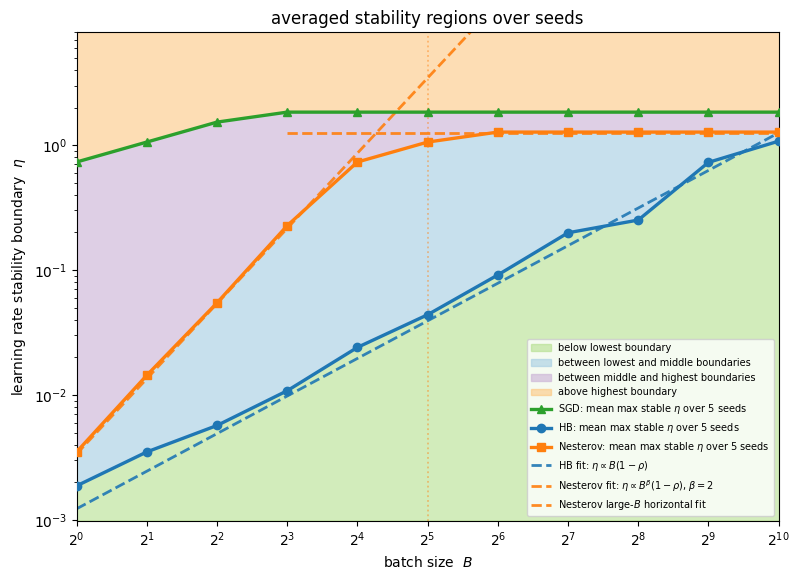

In [12]:

def fit_prefactor(boundary, power, indices=None):
    """
    Fit C in

        eta ~= C * B^power * (1-rho)

    using selected finite boundary points.
    """
    boundary = np.asarray(boundary, dtype=float)

    if indices is None:
        indices = np.arange(len(boundary))
    else:
        indices = np.asarray(indices, dtype=int)

    selected_boundary = boundary[indices]
    selected_B = B_LIST[indices].astype(float)

    mask = np.isfinite(selected_boundary) & (selected_boundary > 0)

    if not np.any(mask):
        return 1.0

    denom = (
        selected_B[mask] ** power
    ) * ONE_MINUS_RHO

    return float(
        np.exp(
            np.mean(
                np.log(
                    selected_boundary[mask] / denom
                )
            )
        )
    )


def fit_horizontal_level(boundary, indices=None):
    """
    Fit a positive horizontal level eta = C_flat.

    The geometric mean is used because the y-axis is logarithmic.
    """
    boundary = np.asarray(boundary, dtype=float)

    if indices is None:
        indices = np.arange(len(boundary))
    else:
        indices = np.asarray(indices, dtype=int)

    selected_boundary = boundary[indices]

    mask = np.isfinite(selected_boundary) & (selected_boundary > 0)

    if not np.any(mask):
        return 1.0

    return float(
        np.exp(
            np.mean(
                np.log(selected_boundary[mask])
            )
        )
    )


def stability_pdf_path():
    tag = (
        f'stability_regions_gpu_3alg_seed{N_SEEDS}_'
        f'beta{BETA:g}_s{S_VALUE:g}_dim{DIM}_'
        f'B{B_EXPONENTS[0]}-{B_EXPONENTS[-1]}_'
        f'eta{ETA_POINTS}_'
        f'omrho{ONE_MINUS_RHO:.0e}_'
        f'K{K_STEPS}_w{WINDOW}_'
        f'thr{STABLE_THRESHOLD:g}'
    ).replace('.', '_').replace('-', 'm')

    return RESULT_DIR / f'{tag}.pdf'


fig, ax = plt.subplots(figsize=(8.1, 5.9))


# ============================================================
# 在这里修改拟合、延长范围和横坐标设置
# ============================================================

# ----------------------------
# HB 拟合线的纵向缩放
# ----------------------------
#
# 1.0：不移动
# > 1.0：向上移动
# < 1.0：向下移动
HB_FIT_SHIFT = 1.0


# ----------------------------
# Nesterov 分段拟合设置
# ----------------------------

# 前多少个点用于幂律拟合。
#
# 例如总共有 10 个点：
# 7 表示前 7 个点拟合幂律，
# 后 3 个点拟合水平线。
NESTEROV_POWER_POINTS = 5


# Nesterov 两段拟合线的纵向缩放
NESTEROV_POWER_SHIFT = 1.0
NESTEROV_FLAT_SHIFT = 1.0


# ----------------------------
# Nesterov 虚线延长设置
# ----------------------------

# 幂律线向右延长的比例。
#
# 延长长度按照水平段点数计算。
# 例如水平段有 3 个点：
# 2/3 表示向右额外延长 ceil(3 * 2/3) = 2 个点。
NESTEROV_POWER_EXTENSION_RATIO = 2 / 3


# 水平线向左延长的比例。
#
# 延长长度按照幂律段点数计算。
# 例如幂律段有 7 个点：
# 1/3 表示向左额外延长 ceil(7 * 1/3) = 3 个点。
NESTEROV_FLAT_EXTENSION_RATIO = 1 / 3


# 是否绘制 Nesterov 分段位置的竖直点线
DRAW_NESTEROV_SPLIT_LINE = True


# ----------------------------
# 横坐标显示范围
# ----------------------------
#
# 横坐标固定显示为：
#
#     2^X_MIN_EXPONENT 到 2^X_MAX_EXPONENT
#
# 当前即为 2^0 到 2^11。
X_MIN_EXPONENT = 0
X_MAX_EXPONENT = 10


styles = {
    'SGD': {
        'color': 'tab:green',
        'marker': '^',
        'power': None,
        'theory_label': None,
    },

    'HB': {
        'color': 'tab:blue',
        'marker': 'o',
        'power': 1.0,
        'theory_label': (
            r'HB fit: $\eta \propto B(1-\rho)$'
        ),
    },

    'Nesterov': {
        'color': 'tab:orange',
        'marker': 's',
        'power': BETA,
        'theory_label_power': (
            rf'Nesterov fit: '
            rf'$\eta \propto B^{{\beta}}(1-\rho)$, '
            rf'$\beta={BETA:g}$'
        ),
        'theory_label_flat': (
            r'Nesterov large-$B$ horizontal fit'
        ),
    },
}


BOUNDARIES = {}
PER_SEED_BOUNDARIES = {}
REFS = {}


# ============================================================
# 计算实验稳定性边界
# ============================================================

for name in ALGOS:
    per_seed = max_stable_eta_per_seed(
        STABLE[name]
    )

    boundary = mean_max_stable_eta(
        STABLE[name]
    )

    PER_SEED_BOUNDARIES[name] = per_seed
    BOUNDARIES[name] = boundary


# ============================================================
# HB 拟合
# ============================================================

hb_boundary = BOUNDARIES['HB']

hb_C = fit_prefactor(
    boundary=hb_boundary,
    power=styles['HB']['power'],
)

hb_C *= HB_FIT_SHIFT

REFS['HB'] = (
    hb_C
    * B_LIST.astype(float) ** styles['HB']['power']
    * ONE_MINUS_RHO
)


# ============================================================
# Nesterov 分段拟合
# ============================================================

num_B = len(B_LIST)

if num_B < 2:
    raise ValueError(
        'Nesterov 分段拟合至少需要两个 batch-size 点。'
    )


# 至少给幂律段和水平段各保留一个点
n_power = int(
    np.clip(
        NESTEROV_POWER_POINTS,
        1,
        num_B - 1,
    )
)


# 真正用于拟合的索引
power_indices = np.arange(
    0,
    n_power,
)

flat_indices = np.arange(
    n_power,
    num_B,
)

nesterov_boundary = BOUNDARIES['Nesterov']


# ============================================================
# Nesterov 前段：幂律拟合
# ============================================================

nesterov_power_C = fit_prefactor(
    boundary=nesterov_boundary,
    power=styles['Nesterov']['power'],
    indices=power_indices,
)

nesterov_power_C *= NESTEROV_POWER_SHIFT

nesterov_power_ref = (
    nesterov_power_C
    * B_LIST.astype(float) ** styles['Nesterov']['power']
    * ONE_MINUS_RHO
)


# ============================================================
# Nesterov 后段：水平线拟合
# ============================================================

nesterov_flat_level = fit_horizontal_level(
    boundary=nesterov_boundary,
    indices=flat_indices,
)

nesterov_flat_level *= NESTEROV_FLAT_SHIFT

nesterov_flat_ref = np.full(
    shape=num_B,
    fill_value=nesterov_flat_level,
    dtype=float,
)


# ============================================================
# 拼接 Nesterov 分段参考边界
#
# 这个数组用于缺失点替换和区域填色。
# 虚线延长范围不会改变这里的分段边界。
# ============================================================

REFS['Nesterov'] = np.empty(
    shape=num_B,
    dtype=float,
)

REFS['Nesterov'][power_indices] = (
    nesterov_power_ref[power_indices]
)

REFS['Nesterov'][flat_indices] = (
    nesterov_flat_ref[flat_indices]
)


# ============================================================
# 计算 Nesterov 两条虚线的绘制范围
#
# 这里只改变虚线画多长，
# 不改变真正用于拟合的数据点。
# ============================================================

power_extension = int(
    np.ceil(
        len(flat_indices)
        * NESTEROV_POWER_EXTENSION_RATIO
    )
)

power_plot_end = min(
    n_power + power_extension,
    num_B,
)

power_plot_indices = np.arange(
    0,
    power_plot_end,
)


flat_extension = int(
    np.ceil(
        len(power_indices)
        * NESTEROV_FLAT_EXTENSION_RATIO
    )
)

flat_plot_start = max(
    n_power - flat_extension,
    0,
)

flat_plot_indices = np.arange(
    flat_plot_start,
    num_B,
)


# ============================================================
# 构造填色区域
# ============================================================

eta_low = float(
    np.min(ETA_GRID)
)

eta_high = float(
    np.max(ETA_GRID)
)


sgd_region = np.where(
    np.isfinite(BOUNDARIES['SGD']),
    BOUNDARIES['SGD'],
    eta_low,
)

hb_region = np.where(
    np.isfinite(BOUNDARIES['HB']),
    BOUNDARIES['HB'],
    REFS['HB'],
)

nes_region = np.where(
    np.isfinite(BOUNDARIES['Nesterov']),
    BOUNDARIES['Nesterov'],
    REFS['Nesterov'],
)


sgd_region = np.clip(
    sgd_region,
    eta_low,
    eta_high,
)

hb_region = np.clip(
    hb_region,
    eta_low,
    eta_high,
)

nes_region = np.clip(
    nes_region,
    eta_low,
    eta_high,
)


# 将三个经验边界在每个 B 处从低到高排序，
# 防止较高的边界覆盖其他区域。
bands = np.sort(
    np.vstack([
        sgd_region,
        hb_region,
        nes_region,
    ]),
    axis=0,
)

band_low = bands[0]
band_mid = bands[1]
band_high = bands[2]


ax.fill_between(
    B_LIST,
    eta_low,
    band_low,
    color='#b2df8a',
    alpha=0.58,
    label='below lowest boundary',
    zorder=0,
)

ax.fill_between(
    B_LIST,
    band_low,
    band_mid,
    color='#a6cee3',
    alpha=0.62,
    label='between lowest and middle boundaries',
    zorder=0,
)

ax.fill_between(
    B_LIST,
    band_mid,
    band_high,
    color='#cab2d6',
    alpha=0.62,
    label='between middle and highest boundaries',
    zorder=0,
)

ax.fill_between(
    B_LIST,
    band_high,
    eta_high,
    color='#fdbf6f',
    alpha=0.52,
    label='above highest boundary',
    zorder=0,
)


# ============================================================
# 绘制实验边界
# ============================================================

for name in ALGOS:
    style = styles[name]
    boundary = BOUNDARIES[name]

    mask = (
        np.isfinite(boundary)
        & (boundary > 0)
    )

    ax.plot(
        B_LIST[mask],
        boundary[mask],
        color=style['color'],
        marker=style['marker'],
        linewidth=2.4,
        label=(
            rf'{name}: mean max stable $\eta$ '
            rf'over {N_SEEDS} seeds'
        ),
        zorder=3,
    )


# ============================================================
# 绘制 HB 拟合虚线
# ============================================================

ax.plot(
    B_LIST,
    REFS['HB'],
    linestyle='--',
    color=styles['HB']['color'],
    alpha=0.9,
    linewidth=2.0,
    label=styles['HB']['theory_label'],
    zorder=2,
)


# ============================================================
# 绘制 Nesterov 幂律拟合虚线
#
# 拟合只使用 power_indices，
# 绘图范围使用 power_plot_indices。
# ============================================================

ax.plot(
    B_LIST[power_plot_indices],
    nesterov_power_ref[power_plot_indices],
    linestyle='--',
    color=styles['Nesterov']['color'],
    alpha=0.9,
    linewidth=2.0,
    label=styles['Nesterov']['theory_label_power'],
    zorder=2,
)


# ============================================================
# 绘制 Nesterov 水平拟合虚线
#
# 拟合只使用 flat_indices，
# 绘图范围使用 flat_plot_indices。
# ============================================================

ax.plot(
    B_LIST[flat_plot_indices],
    nesterov_flat_ref[flat_plot_indices],
    linestyle='--',
    color=styles['Nesterov']['color'],
    alpha=0.9,
    linewidth=2.0,
    label=styles['Nesterov']['theory_label_flat'],
    zorder=2,
)


# ============================================================
# 可选：绘制 Nesterov 分段位置
# ============================================================

if DRAW_NESTEROV_SPLIT_LINE:
    split_B = B_LIST[n_power]

    ax.axvline(
        split_B,
        linestyle=':',
        color=styles['Nesterov']['color'],
        alpha=0.45,
        linewidth=1.3,
        zorder=1,
    )


# ============================================================
# 坐标轴设置
# ============================================================

ax.set_xscale(
    'log',
    base=2,
)

ax.set_yscale('log')


# 横坐标固定为 2^0 到 2^11
ax.set_xlim(
    2 ** X_MIN_EXPONENT,
    2 ** X_MAX_EXPONENT,
)


# 为每个整数次幂设置一个刻度
x_tick_exponents = np.arange(
    X_MIN_EXPONENT,
    X_MAX_EXPONENT + 1,
)

x_ticks = 2.0 ** x_tick_exponents

ax.set_xticks(
    x_ticks
)

ax.set_xticklabels([
    rf'$2^{{{exponent}}}$'
    for exponent in x_tick_exponents
])


ax.set_ylim(
    eta_low,
    eta_high,
)

ax.set_xlabel(
    'batch size  $B$'
)

ax.set_ylabel(
    r'learning rate stability boundary  $\eta$'
)

ax.set_title(
    'averaged stability regions over seeds'
)


# ============================================================
# 图例
# ============================================================

legend_title = ()

ax.legend(
    title=legend_title,
    fontsize=7.0,
    title_fontsize=7.5,
    loc='best',
)


# ============================================================
# 保存和显示
# ============================================================

fig.tight_layout()

PDF_PATH = stability_pdf_path()

fig.savefig(
    PDF_PATH,
    bbox_inches='tight',
)

print(
    f'saved PDF to {PDF_PATH}'
)

plt.show()


## Boundary and minimum-loss table

This table prints both the largest stable `eta` and the lowest final moving-average
loss for each batch size.


In [6]:
for name in ALGOS:
    per_seed_boundary = max_stable_eta_per_seed(STABLE[name])
    boundary = mean_max_stable_eta(STABLE[name])
    print(f'\n{name}: mean max stable eta over {N_SEEDS} seeds and minimum loss by B')
    for j, (B, eta_mean) in enumerate(zip(B_LIST, boundary)):
        eta_text = f'{eta_mean:.3e}' if np.isfinite(eta_mean) else 'nan'
        seed_vals = per_seed_boundary[:, j]
        seed_vals = seed_vals[np.isfinite(seed_vals)]
        eta_std_text = f'{np.std(seed_vals):.3e}' if len(seed_vals) else 'nan'
        min_ma = MIN_FINAL_MA[name][j]
        min_ma_eta = MIN_FINAL_MA_ETA[name][j]
        min_loss = MIN_FINAL_LOSS[name][j]
        min_loss_eta = MIN_FINAL_LOSS_ETA[name][j]
        min_ma_text = f'{min_ma:.3e} @ eta={min_ma_eta:.3e}' if np.isfinite(min_ma) else 'nan'
        min_loss_text = f'{min_loss:.3e} @ eta={min_loss_eta:.3e}' if np.isfinite(min_loss) else 'nan'
        print(f'  B={B:6d}  eta_max_mean={eta_text:>9s}  eta_max_std={eta_std_text:>9s}  min_final_MA={min_ma_text}  min_final_loss={min_loss_text}')

    mask = np.isfinite(boundary) & (boundary > 0)
    if mask.sum() >= 2:
        slope, intercept = np.polyfit(np.log(B_LIST[mask]), np.log(boundary[mask]), 1)
        print(f'  fitted mean-boundary slope d log(eta) / d log(B) = {slope:.3f}')



SGD: mean max stable eta over 5 seeds and minimum loss by B
  B=     1  eta_max_mean=7.326e-01  eta_max_std=0.000e+00  min_final_MA=1.183e-06 @ eta=6.708e-02  min_final_loss=1.122e-06 @ eta=4.219e-01
  B=     2  eta_max_mean=1.058e+00  eta_max_std=0.000e+00  min_final_MA=2.977e-07 @ eta=6.708e-02  min_final_loss=2.968e-07 @ eta=6.708e-02
  B=     4  eta_max_mean=1.529e+00  eta_max_std=0.000e+00  min_final_MA=1.251e-07 @ eta=1.400e-01  min_final_loss=1.233e-07 @ eta=1.400e-01
  B=     8  eta_max_mean=1.837e+00  eta_max_std=2.220e-16  min_final_MA=7.975e-08 @ eta=5.071e-01  min_final_loss=7.266e-08 @ eta=1.058e+00
  B=    16  eta_max_mean=1.837e+00  eta_max_std=2.220e-16  min_final_MA=3.719e-08 @ eta=2.921e-01  min_final_loss=3.682e-08 @ eta=2.921e-01
  B=    32  eta_max_mean=1.837e+00  eta_max_std=2.220e-16  min_final_MA=1.867e-08 @ eta=5.071e-01  min_final_loss=1.843e-08 @ eta=5.071e-01
  B=    64  eta_max_mean=1.837e+00  eta_max_std=2.220e-16  min_final_MA=9.401e-09 @ eta=6.095e-01  